4. Extração de características e construção do dataframe
A equipe deverá transformar cada imagem em um vetor numérico de características. Poderão ser exploradas características de:
- Cor: médias, desvios e histogramas dos canais.
- Textura: LBP e medidas derivadas da matriz de coocorrência.
- Forma: área, perímetro, circularidade, proporções e momentos de Hu.
- Gradientes e bordas: HOG, densidade de bordas e orientação dos gradientes.
  A escolha deverá ser justificada em função do problema. A equipe deverá comparar pelo menos duas configurações de características, por exemplo, cor isoladamente e cor combinada com textura.
O dataframe final deverá conter uma linha por imagem, colunas com as características extraídas, uma coluna com a classe e uma coluna com o identificador da imagem. O identificador não deverá ser utilizado como entrada do classificador.

# Etapa 4 — Extração de características e construção do dataframe

## 4.0 - O que esta etapa faz

Um classificador não "enxerga" imagens: ele só entende números. Nesta etapa, cada imagem
vira uma linha de números chamados **características** (*features*). Juntas, as linhas
formam uma tabela (dataframe) que será usada para treinar e testar os classificadores
na Etapa 5.

As características são medidas **apenas dentro da fruta**, usando a máscara da Etapa 3.
Assim, o fundo branco não influencia os números.

Três grupos de características serão extraídos:
- **Cor:** de que cor é a fruta (médias, desvios e histograma).
- **Textura:** como é a superfície (lisa, rugosa, com manchas): LBP e GLCM.
- **Forma:** o formato da fruta (área, circularidade, proporção, momentos de Hu).

**Configurações a comparar** (os grupos ficarão em colunas separadas para facilitar):
- A: só cor
- B: cor + textura
- C: cor + textura + forma

**Tabela final:** uma linha por imagem, com o identificador da imagem (`id_imagem`),
a classe (a resposta correta), o conjunto (treino ou teste) e as características.
O identificador serve apenas para localizar a imagem e **não pode ser usado como
entrada do classificador**.

In [15]:
# ============================================================
# ETAPA 4 - EXTRAÇÃO DE CARACTERÍSTICAS
# 4.0 - Preparação: bibliotecas, funções das etapas 2 e 3 e dados
# ============================================================

import time
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

# Funções prontas das Etapas 2 e 3 (arquivo preprocessamento.py)
from preprocessamento import carregar_rgb, preprocessar, segmentar, recortar_fruta, normalizar

# scikit-image: usado mais adiante para textura (LBP, GLCM) e HOG
try:
    import skimage
    print("scikit-image instalado, versão", skimage.__version__)
except ImportError:
    print("ATENÇÃO: instale com  pip install scikit-image")

# --- Carregando a seleção da Etapa 1 (25% de cada classe) ---
df_treino = pd.read_csv("treino_reduzido.csv")
df_treino["conjunto"] = "treino"
df_teste = pd.read_csv("teste_reduzido.csv")
df_teste["conjunto"] = "teste"

# Juntamos treino e teste numa tabela só. A coluna "conjunto" lembra a origem
# de cada imagem, para separar de novo na Etapa 5.
df_imagens = pd.concat([df_treino, df_teste]).reset_index(drop=True)

# --- Identificador único da imagem: conjunto/classe/nome do arquivo ---
def criar_id(linha):
    caminho = Path(linha["caminho"])
    return f"{linha['conjunto']}/{linha['classe']}/{caminho.name}"

df_imagens["id_imagem"] = df_imagens.apply(criar_id, axis=1)

print("Total de imagens:", len(df_imagens))
print(df_imagens["conjunto"].value_counts().to_dict())
print("Identificadores únicos?", df_imagens["id_imagem"].is_unique)
display(df_imagens.head())

scikit-image instalado, versão 0.26.0
Total de imagens: 50056
{'treino': 37528, 'teste': 12528}
Identificadores únicos? True


,classe,caminho,conjunto,id_imagem
0,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_85_10...,treino,treino/Almonds 1/r0_85_100.jpg
1,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_17_10...,treino,treino/Almonds 1/r0_17_100.jpg
2,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_10_10...,treino,treino/Almonds 1/r0_10_100.jpg
3,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_302_1...,treino,treino/Almonds 1/r0_302_100.jpg
4,Almonds 1,fruits-360-100x100\Training\Almonds 1\r0_117_1...,treino,treino/Almonds 1/r0_117_100.jpg


### Conclusões do tópico 4.0 — Preparação dos dados

**O que foi feito nesta célula**

1. **Importamos as funções das Etapas 2 e 3.** Elas estão no arquivo `preprocessamento.py`
   (carregar a imagem, pré-processar, segmentar a fruta e normalizar). Assim, a Etapa 4
   usa exatamente o mesmo código das etapas anteriores, sem copiar e colar.

2. **Carregamos a lista de imagens da Etapa 1.** São os arquivos `treino_reduzido.csv` e
   `teste_reduzido.csv`, que contêm 25% das imagens de cada classe.

3. **Juntamos treino e teste numa tabela só.** Para não perder a origem de cada imagem,
   criamos a coluna `conjunto` ("treino" ou "teste"). Na Etapa 5 ela será usada para
   separar os dados de novo: o classificador aprende com o treino e é avaliado no teste.

4. **Criamos o identificador de cada imagem (`id_imagem`).** Ele combina o conjunto, a classe
   e o nome do arquivo, por exemplo `treino/Almonds 1/r0_85_100.jpg`. Isso garante que cada
   imagem tenha um "nome" único na tabela.

**Resultados**

- A tabela tem **50.056 imagens**: 37.528 de treino e 12.528 de teste, os mesmos números
  da Etapa 1.
- Todos os identificadores são **únicos**, ou seja, nenhuma imagem aparece duas vezes
  com o mesmo `id_imagem`.
- A tabela tem, por enquanto, quatro colunas: `classe`, `caminho`, `conjunto` e
  `id_imagem`. As características serão acrescentadas nas próximas células.
- O pacote `scikit-image` (versão 0.26.0) está instalado e será usado para textura
  (LBP e GLCM) e, se necessário, para HOG.

**Um cuidado importante: o identificador não entra no classificador**

O `id_imagem` serve só para localizar a imagem. Ele **não pode ser usado como entrada do
classificador**, porque contém o nome da classe. Se o modelo recebesse essa coluna, ele
"leria" a resposta no próprio identificador e a acurácia ficaria falsamente perfeita, sem
ter aprendido nada sobre as frutas. Pelo mesmo motivo, as colunas `classe`, `caminho` e
`conjunto` também ficam de fora das entradas. Só as colunas de características serão usadas.

**Limitação:** as características serão extraídas da amostra reduzida (25% de cada classe),
e não do dataset completo de 200 mil imagens, conforme decidido na Etapa 1.

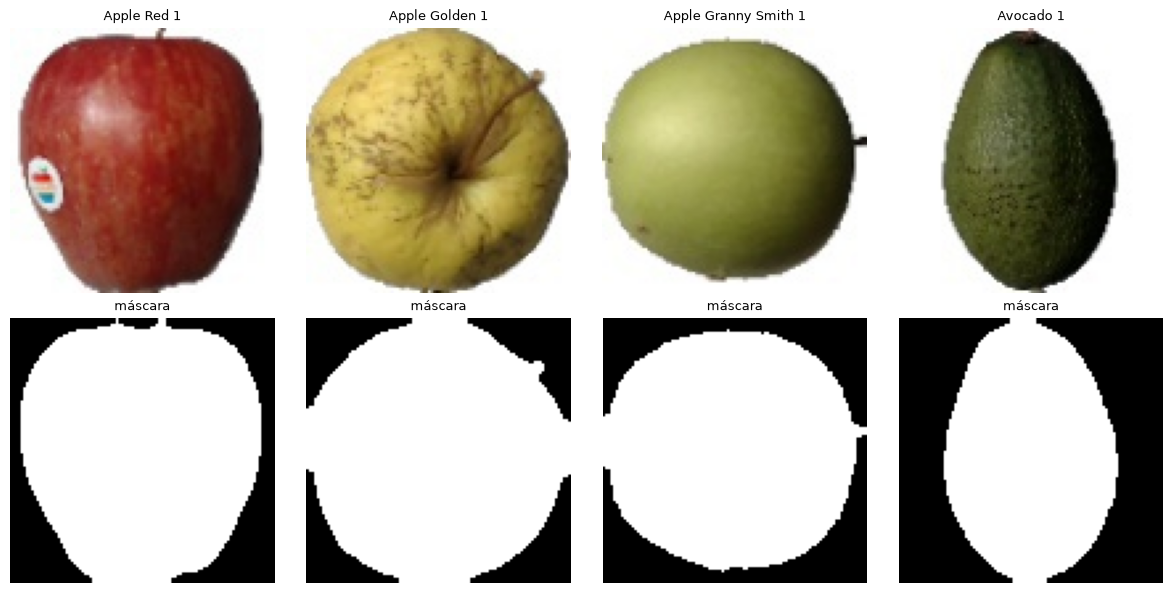

Número de características de cor: 24


,cor_L_media,cor_a_media,cor_b_media,cor_S_media,cor_H_cos,cor_H_sen
Apple Red 1,87.22,159.22,151.23,171.84,0.97,0.13
Apple Golden 1,149.68,127.80,169.15,154.26,0.70,0.70
Apple Granny Smith 1,136.88,118.18,161.46,130.40,0.50,0.87
Avocado 1,60.87,120.98,144.63,146.67,0.31,0.92


In [16]:
# ============================================================
# 4.1 - Características de COR (medidas só dentro da fruta)
# Para cada imagem calculamos:
#   - média e desvio de L, a, b (Lab) e de S, V (HSV)
#   - H tratado como roda de cores: média do cosseno e do seno
#   - histograma do H em 12 faixas (fração de pixels em cada faixa de cor)
# ============================================================

def caracteristicas_cor(img_rgb, mascara):
    """Devolve um dicionário {nome_da_característica: valor}."""
    dentro = mascara > 0                          # True onde é fruta
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

    carac = {}

    # Média e desvio de cada canal, só nos pixels da fruta
    canais = {"L": lab[..., 0], "a": lab[..., 1], "b": lab[..., 2],
              "S": hsv[..., 1], "V": hsv[..., 2]}
    for nome, canal in canais.items():
        valores = canal[dentro].astype(np.float32)
        carac[f"cor_{nome}_media"] = valores.mean()
        carac[f"cor_{nome}_desvio"] = valores.std()

    # H como roda de cores: no OpenCV H vai de 0 a 179, então ângulo = H * 2 graus
    h = hsv[..., 0][dentro].astype(np.float32)
    angulo = np.deg2rad(h * 2)
    carac["cor_H_cos"] = np.cos(angulo).mean()
    carac["cor_H_sen"] = np.sin(angulo).mean()

    # Histograma do H: fração de pixels em cada uma das 12 faixas de cor
    hist, _ = np.histogram(h, bins=12, range=(0, 180))
    hist = hist / max(hist.sum(), 1)              # vira fração (soma = 1)
    for i, valor in enumerate(hist):
        carac[f"cor_H_hist{i:02d}"] = valor

    return carac

# --- Teste em 4 imagens do treino (uma maçã vermelha, uma amarela, uma verde, um abacate) ---
exemplos = ["Apple Red 1", "Apple Golden 1", "Apple Granny Smith 1", "Avocado 1"]
linhas = {}

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j, classe in enumerate(exemplos):
    caminho = df_treino[df_treino["classe"] == classe].sample(1, random_state=3)["caminho"].iloc[0]
    img = preprocessar(carregar_rgb(caminho))
    mascara = segmentar(img, "uniao")
    linhas[classe] = caracteristicas_cor(img, mascara)

    axes[0, j].imshow(img);                axes[0, j].set_title(classe, fontsize=9)
    axes[1, j].imshow(mascara, cmap="gray"); axes[1, j].set_title("máscara", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

tabela = pd.DataFrame(linhas).T
print("Número de características de cor:", tabela.shape[1])
display(tabela[["cor_L_media", "cor_a_media", "cor_b_media", "cor_S_media", "cor_H_cos", "cor_H_sen"]].round(2))

### Conclusões do tópico 4.1 — Características de cor

**O que foi feito**

Para cada imagem, medimos a cor **apenas dentro da fruta** (usando a máscara da Etapa 3),
para o fundo branco não influenciar os números. Cada imagem gera **24 características de cor**:

- **10 de média e desvio:** média e desvio padrão de cinco canais: L, a e b (do Lab) e
  S e V (do HSV). A média diz "qual é a cor típica" e o desvio diz "quanto a cor varia
  dentro da fruta".
- **2 do canal H (matiz):** como o H é uma roda de cores (o vermelho fica nas duas pontas
  da escala), tirar a média direta dá resultados errados. Por isso transformamos o H em um
  ponto na roda (usando cosseno e seno) e tiramos a média desses dois números.
- **12 do histograma do H:** divide a roda de cores em 12 faixas e mede a fração de pixels
  da fruta em cada faixa. Mostra a "mistura de cores" (por exemplo, uma maçã vermelha com
  partes amarelas).

**Resultado do teste (4 frutas do treino)**

| Fruta | L (brilho) | a (verde↔vermelho) | S (saturação) |
|---|---|---|---|
| Apple Red 1 | 87,2 | 159,2 | 171,8 |
| Apple Golden 1 | 149,7 | 127,8 | 154,3 |
| Apple Granny Smith 1 | 136,9 | 118,2 | 130,4 |
| Avocado 1 | 60,9 | 121,0 | 146,7 |

As quatro frutas ficaram com números claramente diferentes. O canal *a* separou a maçã
vermelha (159) da Granny Smith (118), e o brilho L separou o abacate (61), que é escuro,
das maçãs claras. A Golden e a Granny Smith foram as mais parecidas entre si; o canal *a*
e o ângulo do H foram o que mais as distinguiu.

**Limitações**
- O teste foi feito com apenas 4 imagens; não mostra quanto a cor separa as 278 classes.
- A máscara da Etapa 3 pode incluir pixels da borda da fruta e deixar de fora regiões muito
  claras, o que afeta um pouco as médias (efeito não medido).
- A cor sozinha não deve separar variedades muito parecidas (como várias maçãs vermelhas).
  Por isso a Etapa 5 vai comparar cor sozinha com cor combinada a textura e forma.

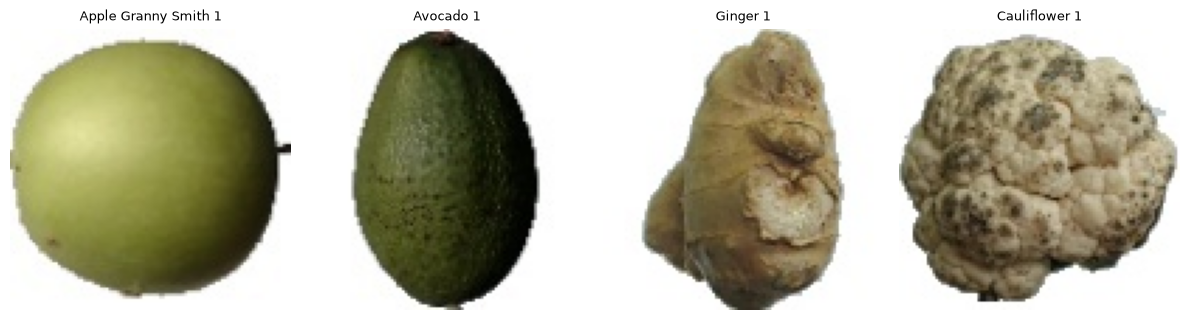

Número de características de textura: 15


,tex_glcm_contrast,tex_glcm_homogeneity,tex_glcm_energy,tex_glcm_correlation,tex_glcm_dissimilarity
Apple Granny Smith 1,0.559,0.898,0.250,0.971,0.246
Avocado 1,1.472,0.789,0.261,0.840,0.530
Ginger 1,1.339,0.702,0.209,0.846,0.708
Cauliflower 1,2.297,0.576,0.152,0.826,1.065


In [17]:
# ============================================================
# 4.2 - Características de TEXTURA (medidas só dentro da fruta)
# LBP: descreve o padrão local da superfície (histograma de 10 padrões)
# GLCM: mede contraste, homogeneidade, energia, correlação e dissimilaridade
# Ambos usam a imagem em tons de cinza.
# ============================================================
from skimage.feature import local_binary_pattern, graycomatrix, graycoprops

def caracteristicas_textura(img_rgb, mascara):
    """Devolve um dicionário {nome_da_característica: valor}."""
    cinza = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    # Encolhemos a máscara 2 pixels para não medir a borda da fruta
    # (na borda, a mudança fruta -> fundo pareceria "textura").
    nucleo = cv2.erode(mascara, np.ones((5, 5), np.uint8))
    dentro = nucleo > 0
    if dentro.sum() < 50:                 # fruta muito pequena: usa a máscara inteira
        dentro = mascara > 0

    carac = {}

    # --- LBP: cada pixel é comparado com os 8 vizinhos ---
    lbp = local_binary_pattern(cinza, P=8, R=1, method="uniform")   # códigos de 0 a 9
    hist, _ = np.histogram(lbp[dentro], bins=10, range=(0, 10))
    hist = hist / max(hist.sum(), 1)      # vira fração (soma = 1)
    for i, valor in enumerate(hist):
        carac[f"tex_lbp{i}"] = valor

    # --- GLCM: cinza reduzido a 16 tons (1 a 16); o fundo vira 0 e é ignorado ---
    quant = (cinza // 16).astype(np.uint8) + 1
    quant[mascara == 0] = 0
    glcm = graycomatrix(quant, distances=[1],
                        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],   # 4 direções
                        levels=17, symmetric=True, normed=False)
    glcm = glcm[1:, 1:, :, :].astype(np.float64)                  # descarta o fundo
    soma = glcm.sum(axis=(0, 1), keepdims=True)
    glcm = glcm / np.where(soma == 0, 1, soma)                     # vira proporção
    for prop in ["contrast", "homogeneity", "energy", "correlation", "dissimilarity"]:
        carac[f"tex_glcm_{prop}"] = graycoprops(glcm, prop).mean() # média das 4 direções

    return carac

# --- Teste: 4 frutas com texturas bem diferentes (lisa x rugosa) ---
exemplos_tex = ["Apple Granny Smith 1", "Avocado 1", "Ginger 1", "Cauliflower 1"]
linhas = {}

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for j, classe in enumerate(exemplos_tex):
    caminho = df_treino[df_treino["classe"] == classe].sample(1, random_state=3)["caminho"].iloc[0]
    img = preprocessar(carregar_rgb(caminho))
    mascara = segmentar(img, "uniao")
    linhas[classe] = caracteristicas_textura(img, mascara)
    axes[j].imshow(img); axes[j].set_title(classe, fontsize=9); axes[j].axis("off")
plt.tight_layout(); plt.show()

tabela_tex = pd.DataFrame(linhas).T
print("Número de características de textura:", tabela_tex.shape[1])
display(tabela_tex[[c for c in tabela_tex.columns if "glcm" in c]].round(3))

### Conclusões do tópico 4.2 — Características de textura

**O que foi feito**

Textura é a "aparência da superfície": lisa, rugosa, com pintinhas ou com manchas. Medimos
a textura **apenas dentro da fruta**, em tons de cinza, com duas técnicas. Cada imagem gera
**15 características de textura**:

- **LBP (10 características).** Para cada pixel, o método compara o tom com os 8 vizinhos
  ("o vizinho é mais claro ou mais escuro?"), o que gera um código. O histograma desses
  códigos mostra a "cara" da superfície (regiões lisas, pontinhos, linhas, cantos).
- **GLCM (5 características).** Conta quantas vezes um tom de cinza aparece ao lado de
  outro. Dessa contagem saem cinco medidas:
  - **Contraste:** quanto maior, mais diferentes são os tons vizinhos (superfície irregular).
  - **Homogeneidade:** quanto maior, mais parecidos são os tons vizinhos (superfície lisa).
  - **Energia:** quanto maior, mais repetitivo é o padrão.
  - **Correlação:** o quanto os tons vizinhos variam juntos.
  - **Dissimilaridade:** parecida com o contraste, mas menos sensível a diferenças grandes.

**Cuidados no cálculo**
- A máscara foi encolhida 2 pixels antes de medir o LBP, para a borda da fruta (onde
  muda de fruta para fundo) não ser confundida com

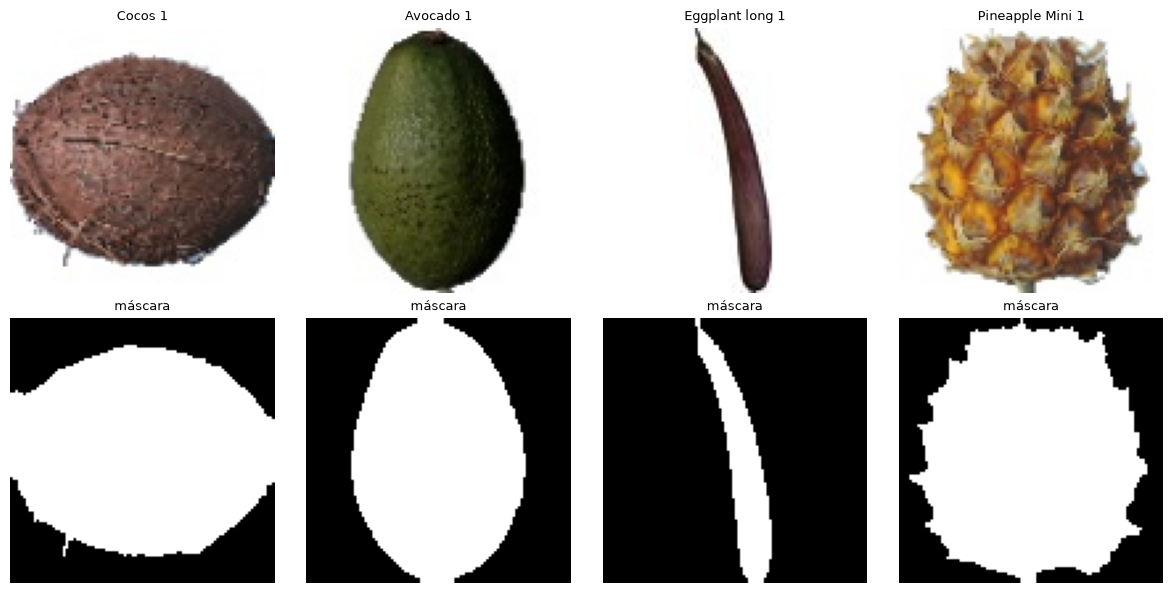

Número de características de forma: 13


,forma_area,forma_circularidade,forma_proporcao,forma_extensao,forma_solidez
Cocos 1,0.615,0.735,1.25,0.768,0.959
Avocado 1,0.483,0.808,0.66,0.732,0.984
Eggplant long 1,0.092,0.227,0.29,0.317,0.764
Pineapple Mini 1,0.627,0.541,0.90,0.697,0.895


In [18]:
# ============================================================
# 4.3 - Características de FORMA (calculadas sobre a máscara da Etapa 3)
# Área, perímetro, circularidade, proporção, preenchimento, solidez
# e os 7 momentos de Hu (formato que não muda com rotação ou tamanho).
# ============================================================

def caracteristicas_forma(mascara):
    """Devolve um dicionário {nome_da_característica: valor}.
    A máscara tem 0 (fundo) e 255 (fruta)."""
    carac = {}
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    if len(contornos) == 0:        # máscara vazia: devolve zeros
        for nome in ["area", "perimetro", "circularidade", "proporcao", "extensao", "solidez"]:
            carac[f"forma_{nome}"] = 0.0
        for i in range(7):
            carac[f"forma_hu{i + 1}"] = 0.0
        return carac

    cnt = max(contornos, key=cv2.contourArea)       # contorno da fruta
    area = cv2.contourArea(cnt)
    perimetro = cv2.arcLength(cnt, True)
    x, y, largura, altura = cv2.boundingRect(cnt)   # caixa que envolve a fruta
    area_convexa = cv2.contourArea(cv2.convexHull(cnt))

    carac["forma_area"] = area / mascara.size                 # fração da imagem (0 a 1)
    carac["forma_perimetro"] = perimetro / mascara.shape[0]   # relativo ao lado da imagem
    carac["forma_circularidade"] = 4 * np.pi * area / (perimetro ** 2) if perimetro > 0 else 0.0
    carac["forma_proporcao"] = largura / altura if altura > 0 else 0.0
    carac["forma_extensao"] = area / (largura * altura) if largura * altura > 0 else 0.0
    carac["forma_solidez"] = area / area_convexa if area_convexa > 0 else 0.0

    # Momentos de Hu: usamos o logaritmo (mantendo o sinal) porque os valores originais
    # são muito pequenos (da ordem de 0,0001) e ficariam "invisíveis" para o classificador.
    hu = cv2.HuMoments(cv2.moments(cnt)).flatten()
    for i, valor in enumerate(hu):
        carac[f"forma_hu{i + 1}"] = -np.sign(valor) * np.log10(abs(valor) + 1e-30)

    return carac

# --- Teste: formas bem diferentes (redonda, oval, alongada, irregular) ---
exemplos_forma = ["Cocos 1", "Avocado 1", "Eggplant long 1", "Pineapple Mini 1"]
linhas = {}

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j, classe in enumerate(exemplos_forma):
    caminho = df_treino[df_treino["classe"] == classe].sample(1, random_state=3)["caminho"].iloc[0]
    img = preprocessar(carregar_rgb(caminho))
    mascara = segmentar(img, "uniao")
    linhas[classe] = caracteristicas_forma(mascara)
    axes[0, j].imshow(img);                  axes[0, j].set_title(classe, fontsize=9)
    axes[1, j].imshow(mascara, cmap="gray"); axes[1, j].set_title("máscara", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

tabela_forma = pd.DataFrame(linhas).T
print("Número de características de forma:", tabela_forma.shape[1])
display(tabela_forma[["forma_area", "forma_circularidade", "forma_proporcao",
                      "forma_extensao", "forma_solidez"]].round(3))

### Conclusões do tópico 4.3 — Características de forma

**O que foi feito**

Forma é o "formato" da fruta: redonda, oval, comprida, com pontas. Medimos a forma a partir
da **máscara da Etapa 3** (a silhueta da fruta). Cada imagem gera **13 características**:

- **Área:** quanto da imagem a fruta ocupa (de 0 a 1).
- **Perímetro:** o tamanho do contorno da fruta, relativo ao lado da imagem.
- **Circularidade:** 1 é um círculo perfeito; valores menores indicam formas alongadas ou
  irregulares.
- **Proporção:** largura dividida pela altura da caixa que envolve a fruta. Abaixo de 1, a
  fruta é mais alta que larga.
- **Extensão:** quanto da caixa que envolve a fruta ela preenche.
- **Solidez:** o quanto a fruta preenche a sua "casca convexa" (o contorno esticado, como um
  elástico em volta). Valores baixos indicam curvas ou reentrâncias.
- **7 momentos de Hu:** números que descrevem o formato e **não mudam se a fruta for
  girada, movida ou ampliada**. Usamos o logaritmo deles porque os valores originais são
  muito pequenos e o classificador quase não os "enxergaria".

**Resultado do teste (4 frutas do treino)**

| Fruta | Área | Circularidade | Proporção | Solidez |
|---|---|---|---|---|
| Cocos 1 | 0,615 | 0,735 | 1,25 | 0,959 |
| Avocado 1 | 0,483 | 0,808 | 0,66 | 0,984 |
| Eggplant long 1 | 0,092 | 0,227 | 0,29 | 0,764 |
| Pineapple Mini 1 | 0,627 | 0,541 | 0,90 | 0,895 |

A berinjela, comprida e fina, teve a menor área (9% da imagem), a menor circularidade e a menor
proporção. O abacaxi, com contorno cheio de pontas, teve circularidade baixa (0,541).

**Resultados diferentes do esperado**
- Esperávamos que o coco tivesse a circularidade mais alta. Quem teve foi o abacate (0,808).
  O coco é mais largo que alto (proporção 1,25) e a máscara dele tem irregularidades na borda
  inferior, mas não medimos quanto cada fator pesa.
- Esperávamos que o abacaxi tivesse a menor solidez. Quem teve foi a berinjela (0,764),
  provavelmente por ser curva, o que aumenta a casca convexa. É uma explicação provável,
  não verificada.

**Limitações**
- O teste foi feito com 4 imagens, e não mostra quanto a forma separa as 278 classes.
- A forma depende da máscara. Onde a máscara falha (reflexos, cascas claras, como a Apple 8
  da Etapa 3), a forma também fica errada.
- A máscara tem pequenas saliências onde a fruta toca a borda da imagem (por exemplo, o talo
  do abacate), que aumentam o perímetro e reduzem a circularidade. O tamanho desse efeito
  não foi medido.
- Frutas cortadas pela borda da imagem (como o coco) têm a forma "incompleta".
- Muitas frutas diferentes têm formas parecidas (várias maçãs redondas), então a forma
  sozinha não separa variedades próximas. A Etapa 5 vai verificar se acrescentar forma à
  cor e à textura ajuda.

In [19]:
# ============================================================
# 4.4 - Extração completa de UMA imagem e teste de tempo
# Junta cor + textura + forma. Antes de rodar nas 50.056 imagens,
# medimos o tempo em 200 imagens para estimar a duração total.
# ============================================================

def extrair_caracteristicas(caminho):
    """Lê uma imagem e devolve um dicionário com todas as características."""
    img = preprocessar(carregar_rgb(caminho))
    mascara = segmentar(img, "uniao")

    # Segurança: se a segmentação não achou fruta nenhuma, usamos a imagem inteira
    # e deixamos uma marca (coluna de controle, que NÃO é característica).
    vazia = int((mascara > 0).sum() == 0)
    if vazia:
        mascara = np.full_like(mascara, 255)

    carac = {}
    carac.update(caracteristicas_cor(img, mascara))
    carac.update(caracteristicas_textura(img, mascara))
    carac.update(caracteristicas_forma(mascara))
    carac["controle_mascara_vazia"] = vazia
    return carac

# --- Teste de tempo em 200 imagens ---
amostra_tempo = df_imagens.sample(200, random_state=0)

inicio = time.perf_counter()
resultados = [extrair_caracteristicas(c) for c in amostra_tempo["caminho"]]
duracao = time.perf_counter() - inicio

df_teste_tempo = pd.DataFrame(resultados)
colunas_carac = [c for c in df_teste_tempo.columns if not c.startswith("controle_")]

print(f"Tempo por imagem: {duracao / 200 * 1000:.1f} ms")
print(f"Estimativa para {len(df_imagens)} imagens: {duracao / 200 * len(df_imagens) / 60:.1f} minutos")
print("Número de características:", len(colunas_carac))
print("Valores ausentes (NaN):", int(df_teste_tempo[colunas_carac].isna().sum().sum()))
print("Valores infinitos:", int(np.isinf(df_teste_tempo[colunas_carac]).sum().sum()))
print("Máscaras vazias:", int(df_teste_tempo["controle_mascara_vazia"].sum()))

Tempo por imagem: 12.7 ms
Estimativa para 50056 imagens: 10.6 minutos
Número de características: 52
Valores ausentes (NaN): 0
Valores infinitos: 0
Máscaras vazias: 0


### Conclusões do tópico 4.4 — Juntando cor, textura e forma

**O que foi feito**

Criamos uma função (`extrair_caracteristicas`) que recebe o caminho de uma imagem e devolve
todas as características dela. Em ordem, ela:

1. carrega a imagem e aplica o pré-processamento da Etapa 2;
2. segmenta a fruta com o método da Etapa 3 (união dos dois métodos);
3. calcula as características de **cor** (24), de **textura** (15) e de **forma** (13);
4. acrescenta uma coluna de controle, `controle_mascara_vazia`, que vale 1 se a
   segmentação não encontrou nenhuma fruta (nesse caso, a imagem inteira é usada).
   Essa coluna serve só para conferir a qualidade e **não é uma característica**.

**Teste em 200 imagens do treino**

- Cada imagem levou cerca de 24 ms; a estimativa era de 20 minutos para as 50.056 imagens.
- Cada imagem gerou **52 características** (24 + 15 + 13).
- Não houve valores ausentes (NaN), valores infinitos nem máscaras vazias.

**Limitação:** a estimativa de tempo foi menor que o tempo real da extração completa
(ver tópico 4.5).

In [20]:
# ============================================================
# 4.5 - Extração completa (50.056 imagens) e construção do dataframe
# Processa em blocos de 5.000 imagens e salva cada bloco num arquivo.
# Se o VS Code travar ou o kernel reiniciar, basta rodar a célula de novo:
# os blocos já prontos são pulados e o trabalho continua de onde parou.
# ============================================================

TAM_BLOCO = 5000
pasta_blocos = Path("caracteristicas_parciais")
pasta_blocos.mkdir(exist_ok=True)

falhas = []                                   # imagens que não puderam ser processadas
n_blocos = int(np.ceil(len(df_imagens) / TAM_BLOCO))
inicio_total = time.perf_counter()

for b in range(n_blocos):
    arquivo = pasta_blocos / f"bloco_{b:03d}.csv"
    if arquivo.exists():
        print(f"Bloco {b + 1}/{n_blocos}: já existe, pulando")
        continue

    bloco = df_imagens.iloc[b * TAM_BLOCO:(b + 1) * TAM_BLOCO]
    registros = []
    for id_img, classe, conjunto, caminho in zip(bloco["id_imagem"], bloco["classe"],
                                                 bloco["conjunto"], bloco["caminho"]):
        try:
            registro = {"id_imagem": id_img, "classe": classe, "conjunto": conjunto}
            registro.update(extrair_caracteristicas(caminho))
            registros.append(registro)
        except Exception as erro:             # uma imagem ruim não derruba o processo
            falhas.append((id_img, str(erro)))

    pd.DataFrame(registros).to_csv(arquivo, index=False)
    minutos = (time.perf_counter() - inicio_total) / 60
    print(f"Bloco {b + 1}/{n_blocos}: {len(registros)} imagens ok | {minutos:.1f} min desde o início")

# --- Junta todos os blocos na tabela final ---
df_carac = pd.concat([pd.read_csv(a) for a in sorted(pasta_blocos.glob("bloco_*.csv"))],
                     ignore_index=True)
df_carac.to_csv("caracteristicas.csv", index=False)

print("\nTabela final:", df_carac.shape)
print("Imagens com falha:", len(falhas))
display(df_carac.head())

Bloco 1/11: já existe, pulando
Bloco 2/11: já existe, pulando
Bloco 3/11: já existe, pulando
Bloco 4/11: já existe, pulando
Bloco 5/11: já existe, pulando
Bloco 6/11: já existe, pulando
Bloco 7/11: já existe, pulando
Bloco 8/11: já existe, pulando
Bloco 9/11: já existe, pulando
Bloco 10/11: já existe, pulando
Bloco 11/11: já existe, pulando

Tabela final: (50056, 56)
Imagens com falha: 0


,id_imagem,classe,conjunto,cor_L_media,cor_L_desvio,cor_a_media,cor_a_desvio,cor_b_media,cor_b_desvio,cor_S_media,...,forma_extensao,forma_solidez,forma_hu1,forma_hu2,forma_hu3,forma_hu4,forma_hu5,forma_hu6,forma_hu7,controle_mascara_vazia
0,treino/Almonds 1/r0_85_100.jpg,Almonds 1,treino,51.780663,34.303783,136.62280,5.653486,141.29265,8.824656,140.23897,...,0.728804,0.969491,0.665961,1.682734,4.192079,4.944068,9.571818,5.895860,-9.821775,0
1,treino/Almonds 1/r0_17_100.jpg,Almonds 1,treino,66.767570,28.021780,139.85577,5.341093,146.15120,7.690400,154.03217,...,0.726250,0.965597,0.622682,1.508692,4.184589,4.711100,9.163869,5.537652,9.983655,0
2,treino/Almonds 1/r0_10_100.jpg,Almonds 1,treino,69.735400,27.280859,140.34497,4.859796,146.62040,7.473475,153.24823,...,0.726047,0.963580,0.638730,1.570880,4.363401,5.234318,10.113439,6.433625,10.288197,0
3,treino/Almonds 1/r0_302_100.jpg,Almonds 1,treino,74.334750,26.008146,140.12225,4.737120,147.72125,7.358060,151.86500,...,0.732264,0.963386,0.690045,1.809306,4.066016,5.175187,9.841608,6.259481,-10.156149,0
4,treino/Almonds 1/r0_117_100.jpg,Almonds 1,treino,69.733536,29.311237,138.10931,5.136219,145.23009,7.565405,142.51254,...,0.777971,0.972112,0.769461,2.506373,4.446797,5.905580,-11.116897,-7.173687,11.494649,0


### Conclusões do tópico 4.5 — Extração completa e construção do dataframe

**O que foi feito**

A função do tópico 4.4 foi aplicada às **50.056 imagens** (37.528 de treino e 12.528 de
teste), em 11 blocos de 5.000. Cada bloco foi salvo em um arquivo; assim, se o programa
parasse no meio, o trabalho continuaria de onde parou. No final, os blocos foram juntados
e a tabela completa foi salva em `caracteristicas.csv`.

**Resultado**

- A tabela final tem **50.056 linhas e 56 colunas**: uma linha por imagem.
- As 56 colunas são: `id_imagem` (identificador), `classe` (a resposta correta),
  `conjunto` (treino ou teste), 52 características e a coluna de controle
  `controle_mascara_vazia`.
- **Nenhuma imagem falhou** durante o processamento.
- O processamento levou **31,5 minutos**, mais que os 20 minutos estimados no teste de
  200 imagens. Não investigamos o motivo.

**Observação sobre os momentos de Hu**

Nas primeiras linhas da tabela, os momentos de Hu 5, 6 e 7 mudam de sinal entre imagens da
mesma classe (por exemplo, o `forma_hu7` de Almonds 1 aparece como -9,8, +10,0 e +11,5).
Isso provavelmente acontece porque esses momentos mudam de sinal quando a forma aparece
espelhada, e as frutas aparecem em orientações diferentes dentro de uma mesma classe. Não
verificamos essa explicação. Mantivemos as colunas; a Etapa 5 pode avaliar se ajudam.

**Cuidado importante: o que NÃO entra no classificador**

`id_imagem`, `classe`, `conjunto` e `controle_mascara_vazia` **não são características**.
O `id_imagem` contém o nome da classe, e a `classe` é a resposta que o classificador deve
descobrir. Se qualquer uma entrasse como entrada, a acurácia ficaria falsamente alta.
Apenas as 52 colunas que começam com `cor_`, `tex_` e `forma_` devem ser usadas como entrada.

**Limitações**
- As características foram extraídas da amostra reduzida (25% de cada classe), conforme a
  Etapa 1.
- Todas dependem da máscara da Etapa 3, que pode falhar em reflexos e regiões muito claras.
  Não há como medir a taxa de falhas, pois não existe máscara de referência.
- As escalas das características são muito diferentes (por exemplo, a média de L vai até 255
  e a circularidade vai de 0 a 1). Se o classificador for sensível a escala, será preciso
  padronizá-las na Etapa 5, ajustando a padronização só com o conjunto de treino.

In [21]:
# ============================================================
# 4.6 - Verificação da tabela final
# ============================================================

colunas_carac = [c for c in df_carac.columns
                 if c.startswith(("cor_", "tex_", "forma_"))]

print("Linhas:", len(df_carac), "| Colunas de características:", len(colunas_carac))
print("Identificadores únicos?", df_carac["id_imagem"].is_unique)
print("Classes:", df_carac["classe"].nunique())
print("Conjuntos:", df_carac["conjunto"].value_counts().to_dict())
print("Valores ausentes (NaN):", int(df_carac[colunas_carac].isna().sum().sum()))
print("Valores infinitos:", int(np.isinf(df_carac[colunas_carac]).sum().sum()))
print("Máscaras vazias:", int(df_carac["controle_mascara_vazia"].sum()))

# --- As três configurações a comparar na Etapa 5 ---
cols_cor = [c for c in colunas_carac if c.startswith("cor_")]
cols_tex = [c for c in colunas_carac if c.startswith("tex_")]
cols_forma = [c for c in colunas_carac if c.startswith("forma_")]
configuracoes = {
    "A: so cor": cols_cor,
    "B: cor + textura": cols_cor + cols_tex,
    "C: cor + textura + forma": cols_cor + cols_tex + cols_forma,
}
for nome, colunas in configuracoes.items():
    print(f"{nome}: {len(colunas)} características")

# --- Estatísticas de algumas características (conferir se são razoáveis) ---
display(df_carac[["cor_L_media", "cor_S_media", "tex_glcm_contrast",
                  "forma_area", "forma_circularidade"]].describe().round(3))

Linhas: 50056 | Colunas de características: 52
Identificadores únicos? True
Classes: 279
Conjuntos: {'treino': 37528, 'teste': 12528}
Valores ausentes (NaN): 0
Valores infinitos: 0
Máscaras vazias: 0
A: so cor: 24 características
B: cor + textura: 39 características
C: cor + textura + forma: 52 características


,cor_L_media,cor_S_media,tex_glcm_contrast,forma_area,forma_circularidade
count,50056.000,50056.000,50056.000,50056.000,50056.000
mean,91.198,136.465,0.938,0.601,0.759
std,38.837,49.643,0.502,0.148,0.129
min,16.680,12.055,0.158,0.038,0.098
25%,60.098,97.888,0.632,0.517,0.709
50%,88.424,138.174,0.825,0.642,0.806
75%,115.199,174.916,1.099,0.716,0.854
max,216.999,237.970,5.428,0.835,0.901


In [22]:
# ============================================================
# 4.7 - Correção de classes escritas de formas diferentes
# O dataset tem uma classe cujo nome muda só nas maiúsculas/minúsculas entre
# as pastas Training e Test (identificado na Etapa 1). Aqui unificamos o nome,
# usando a grafia do conjunto de treino como padrão.
# ============================================================

# Passo 1: encontrar classes com mais de uma grafia
grupos = df_carac.groupby(df_carac["classe"].str.casefold())["classe"].unique()
duplicadas = grupos[grupos.apply(len) > 1]
print("Classes com mais de uma grafia:", len(duplicadas))
for chave, grafias in duplicadas.items():
    print("\n", list(grafias))
    print(df_carac[df_carac["classe"].isin(grafias)].groupby(["classe", "conjunto"]).size())

# Passo 2: unificar usando a grafia do treino
mapa = {}
for chave, grafias in duplicadas.items():
    grafias_treino = df_carac.loc[(df_carac["conjunto"] == "treino")
                                  & df_carac["classe"].isin(grafias), "classe"].unique()
    padrao = grafias_treino[0] if len(grafias_treino) > 0 else grafias[0]
    for g in grafias:
        mapa[g] = padrao
print("\nCorreção aplicada:", mapa)
df_carac["classe"] = df_carac["classe"].replace(mapa)

# Passo 3: conferir
print("\nClasses depois da correção:", df_carac["classe"].nunique())
classes_treino_c = set(df_carac.loc[df_carac["conjunto"] == "treino", "classe"])
classes_teste_c = set(df_carac.loc[df_carac["conjunto"] == "teste", "classe"])
print("Mesmas classes no treino e no teste?", classes_treino_c == classes_teste_c)

# Passo 4: salvar de novo a tabela corrigida
df_carac.to_csv("caracteristicas.csv", index=False)

Classes com mais de uma grafia: 1

 ['BlackBerry 4', 'Blackberry 4']
classe        conjunto
BlackBerry 4  treino      110
Blackberry 4  teste        36
dtype: int64

Correção aplicada: {'BlackBerry 4': 'BlackBerry 4', 'Blackberry 4': 'BlackBerry 4'}

Classes depois da correção: 278
Mesmas classes no treino e no teste? True


### Conclusões do tópico 4.6 — Verificação da tabela final

**O que foi verificado**

Depois da extração, conferimos se a tabela estava correta e completa:

- **Tamanho:** 50.056 linhas (37.528 de treino e 12.528 de teste) e 52 colunas de
  características.
- **Identificadores:** todos os `id_imagem` são únicos.
- **Problemas nos números:** nenhum valor ausente (NaN), nenhum valor infinito e nenhuma
  máscara vazia.
- **Valores razoáveis:** a circularidade ficou entre 0,098 e 0,901 (nunca passa de 1, como
  deve ser) e a área da fruta entre 3,8% e 83,5% da imagem. O brilho médio (L) tem média de
  91,2, e a média da área da fruta é de 60,1% da imagem.

**Problema encontrado: 279 classes em vez de 278**

A verificação mostrou **279 classes**, e a Etapa 1 tinha encontrado 278. A causa é uma
classe escrita de dois jeitos: **"BlackBerry 4"** (110 imagens de treino) e **"Blackberry 4"**
(36 imagens de teste), que só diferem nas letras maiúsculas. O computador trata os dois nomes
como classes diferentes, mas é a mesma classe.

Se isso não fosse corrigido, o classificador da Etapa 5 não teria exemplos de teste para uma
delas nem exemplos de treino para a outra, e as métricas seriam distorcidas.

**Correção:** unificamos o nome, usando a grafia do conjunto de treino ("BlackBerry 4").
Depois disso, a tabela tem **278 classes**, e as mesmas classes aparecem no treino e no
teste. A coluna `id_imagem` não foi alterada (ela mantém o caminho original e nunca é usada
como entrada).

**Atenção para as próximas etapas:** os arquivos `treino_reduzido.csv` e `teste_reduzido.csv`
da Etapa 1 continuam com as duas grafias. A Etapa 5 deve usar a coluna `classe` do arquivo
`caracteristicas.csv` (já corrigido).

**Limitação:** a verificação confere se os números são plausíveis, mas não prova que cada
característica foi calculada de forma correta em todas as imagens. A conferência foi feita
em estatísticas gerais e em exemplos.

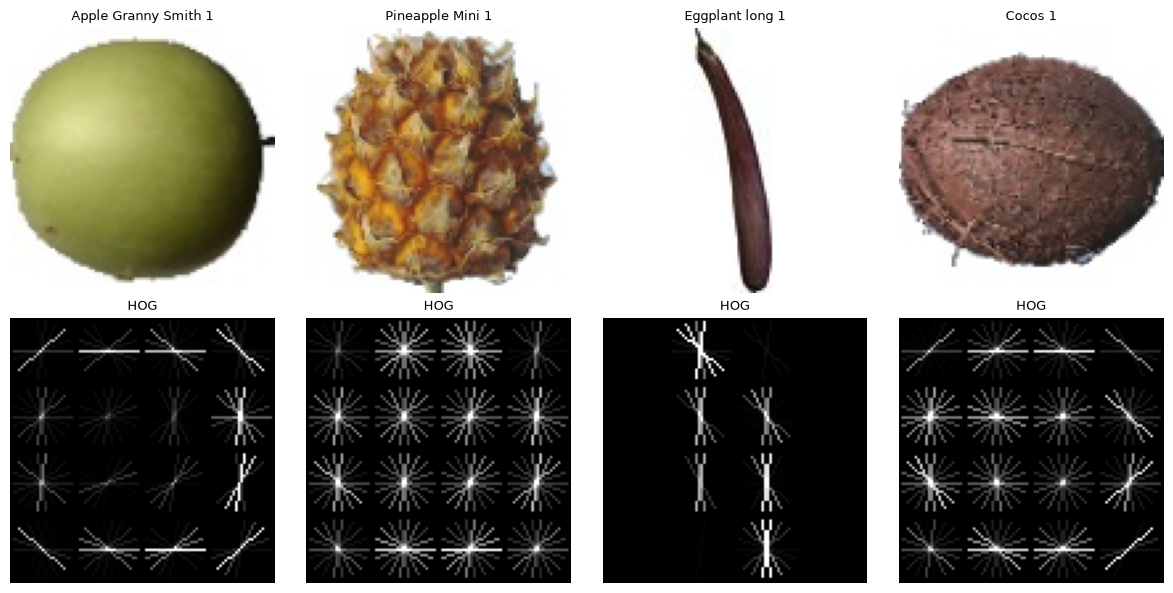

Formato: (200, 324) | tipo: float32
Tempo por imagem: 5.6 ms
Estimativa para 50056 imagens: 4.7 minutos
NaN: 0 | infinitos: 0


In [23]:
# ============================================================
# 4.8 - HOG compacto (Histograma de Gradientes Orientados)
# O HOG divide a imagem em quadrados de 25x25 pixels e, em cada um, conta para
# que direção apontam as bordas (9 direções). Os quadrados são agrupados em
# blocos de 2x2 e normalizados. Resultado: 324 números por imagem.
# Calculado em tons de cinza, sobre a fruta recortada (fundo branco).
# ============================================================
from skimage.feature import hog
from skimage import exposure

def caracteristicas_hog(img_rgb, mascara):
    """Devolve um vetor com 324 números (float32)."""
    fruta = recortar_fruta(img_rgb, mascara)          # fundo branco constante
    cinza = cv2.cvtColor(fruta, cv2.COLOR_RGB2GRAY)
    return hog(cinza, orientations=9, pixels_per_cell=(25, 25), cells_per_block=(2, 2),
               block_norm="L2-Hys", feature_vector=True).astype(np.float32)

def extrair_hog(caminho):
    """Lê uma imagem, segmenta e devolve o HOG dela."""
    img = preprocessar(carregar_rgb(caminho))
    mascara = segmentar(img, "uniao")
    if (mascara > 0).sum() == 0:                      # segurança: máscara vazia
        mascara = np.full_like(mascara, 255)
    return caracteristicas_hog(img, mascara)

# --- Visualização: como o HOG "enxerga" 4 frutas ---
exemplos_hog = ["Apple Granny Smith 1", "Pineapple Mini 1", "Eggplant long 1", "Cocos 1"]
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for j, classe in enumerate(exemplos_hog):
    caminho = df_treino[df_treino["classe"] == classe].sample(1, random_state=3)["caminho"].iloc[0]
    img = preprocessar(carregar_rgb(caminho))
    mascara = segmentar(img, "uniao")
    cinza = cv2.cvtColor(recortar_fruta(img, mascara), cv2.COLOR_RGB2GRAY)
    _, imagem_hog = hog(cinza, orientations=9, pixels_per_cell=(25, 25), cells_per_block=(2, 2),
                        block_norm="L2-Hys", visualize=True)
    axes[0, j].imshow(img); axes[0, j].set_title(classe, fontsize=9)
    axes[1, j].imshow(exposure.rescale_intensity(imagem_hog, in_range=(0, 10)), cmap="gray")
    axes[1, j].set_title("HOG", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout(); plt.show()

# --- Teste de tempo em 200 imagens ---
amostra_hog = df_imagens.sample(200, random_state=0)
inicio = time.perf_counter()
teste_hog = np.vstack([extrair_hog(c) for c in amostra_hog["caminho"]])
duracao = time.perf_counter() - inicio
print(f"Formato: {teste_hog.shape} | tipo: {teste_hog.dtype}")
print(f"Tempo por imagem: {duracao / 200 * 1000:.1f} ms")
print(f"Estimativa para {len(df_imagens)} imagens: {duracao / 200 * len(df_imagens) / 60:.1f} minutos")
print("NaN:", int(np.isnan(teste_hog).sum()), "| infinitos:", int(np.isinf(teste_hog).sum()))

### Conclusões do tópico 4.8 — Características de gradientes e bordas (HOG)

**O que é o HOG, em palavras simples**

O HOG (Histograma de Gradientes Orientados) descreve **para onde apontam as bordas** de uma
imagem. A imagem é dividida em quadrados e, em cada um, o método conta quantas bordas são
horizontais, verticais ou diagonais. Quadrados lisos quase não têm bordas; quadrados com
textura têm bordas em várias direções.

**Como foi calculado**

- A imagem foi convertida para tons de cinza e a fruta foi recortada com fundo branco
  (usando a máscara da Etapa 3), para o ruído do fundo não gerar bordas falsas.
- Quadrados de **25x25 pixels** (a imagem fica com 4x4 quadrados), **9 direções** de borda e
  blocos de 2x2 quadrados com normalização.
- Cada imagem gera **324 números**.
- Escolhemos quadrados grandes para limitar o número de colunas. Com os quadrados padrão
  (8x8 pixels), seriam 8.100 colunas por imagem, e o arquivo ficaria grande demais para o GitHub.

**O que a visualização mostrou (4 frutas do treino)**

- **Maçã Granny Smith (lisa):** o interior do HOG ficou fraco e as bordas fortes aparecem só
  na beirada, acompanhando o contorno.
- **Abacaxi (casca com escamas):** todos os quadrados mostraram bordas em muitas direções.
- **Berinjela (fina e em pé):** só duas colunas de quadrados tiveram bordas, quase todas verticais.
- **Coco:** bordas na beirada e bordas em muitas direções no interior, por causa das fibras.

O HOG distinguiu superfícies lisas de texturizadas e registrou a silhueta da fruta.

**Teste em 200 imagens do treino:** formato (200, 324), sem valores ausentes nem infinitos, e
tempo de cerca de 6 ms por imagem (estimativa de 5,2 minutos para as 50.056 imagens).

**Limitações**
- O HOG compara direções de borda em **posições fixas da imagem**. As frutas aparecem em
  orientações diferentes dentro de uma mesma classe, então uma fruta girada gera um HOG
  diferente (efeito não medido).
- A silhueta da fruta entra no HOG, então ele se sobrepõe em parte às características de forma.
- Com apenas 4x4 quadrados, o HOG é grosseiro e não descreve detalhes finos.
- Os parâmetros (tamanho do quadrado, número de direções) foram escolhidos por limite de
  tamanho do arquivo, sem comparar alternativas.
- A utilidade real do HOG só será conhecida na Etapa 5, comparando a configuração com HOG
  (D) com as demais.

In [24]:
# ============================================================
# 4.9 - Extração completa do HOG (50.056 imagens), em blocos de 5.000
# Cada bloco é salvo; se travar, rode a célula de novo e ela continua.
# Resultado final: hog.npz, com os identificadores (ids) e a matriz HOG (X).
# ============================================================

TAM_BLOCO = 5000
pasta_hog = Path("hog_parciais")
pasta_hog.mkdir(exist_ok=True)

falhas_hog = []
n_blocos = int(np.ceil(len(df_imagens) / TAM_BLOCO))
inicio_total = time.perf_counter()

for b in range(n_blocos):
    arquivo = pasta_hog / f"bloco_{b:03d}.npz"
    if arquivo.exists():
        print(f"Bloco {b + 1}/{n_blocos}: já existe, pulando")
        continue
    bloco = df_imagens.iloc[b * TAM_BLOCO:(b + 1) * TAM_BLOCO]
    ids, linhas = [], []
    for id_img, caminho in zip(bloco["id_imagem"], bloco["caminho"]):
        try:
            linhas.append(extrair_hog(caminho))
            ids.append(id_img)
        except Exception as erro:
            falhas_hog.append((id_img, str(erro)))
    np.savez(arquivo, ids=np.array(ids), X=np.vstack(linhas))
    minutos = (time.perf_counter() - inicio_total) / 60
    print(f"Bloco {b + 1}/{n_blocos}: {len(ids)} imagens ok | {minutos:.1f} min desde o início")

# --- Junta os blocos e salva ---
ids_todos, X_todos = [], []
for a in sorted(pasta_hog.glob("bloco_*.npz")):
    d = np.load(a)
    ids_todos.append(d["ids"]); X_todos.append(d["X"])
ids_todos = np.concatenate(ids_todos)
X_todos = np.vstack(X_todos)
np.savez("hog.npz", ids=ids_todos, X=X_todos)

print("\nHOG:", X_todos.shape, "| falhas:", len(falhas_hog))
print("Mesmos identificadores da tabela principal?", set(ids_todos) == set(df_carac["id_imagem"]))
print("NaN:", int(np.isnan(X_todos).sum()), "| infinitos:", int(np.isinf(X_todos).sum()))

Bloco 1/11: já existe, pulando
Bloco 2/11: já existe, pulando
Bloco 3/11: já existe, pulando
Bloco 4/11: já existe, pulando
Bloco 5/11: já existe, pulando
Bloco 6/11: já existe, pulando
Bloco 7/11: já existe, pulando
Bloco 8/11: já existe, pulando
Bloco 9/11: já existe, pulando
Bloco 10/11: já existe, pulando
Bloco 11/11: já existe, pulando

HOG: (50056, 324) | falhas: 0
Mesmos identificadores da tabela principal? True
NaN: 0 | infinitos: 0


### Conclusões do tópico 4.9 — Extração completa do HOG

O HOG foi calculado para as **50.056 imagens**, em 11 blocos de 5.000, com os mesmos
identificadores da tabela principal. O resultado é uma matriz de **50.056 linhas e 324
colunas**, salva no arquivo `hog.npz` junto com a lista de identificadores (`ids`).

- **Nenhuma imagem falhou**, e não há valores ausentes (NaN) nem infinitos.
- Os identificadores do HOG são exatamente os mesmos de `caracteristicas.csv`, então as duas
  tabelas podem ser juntadas pela coluna `id_imagem`.
- O processamento levou **6,9 minutos**, mais que os 5,2 estimados no teste de 200 imagens.

**Por que o HOG ficou num arquivo separado:** com 324 colunas a mais, o arquivo CSV passaria
de 150 MB e não caberia no GitHub. O formato `.npz` (números de 32 bits) ocupa bem menos.

**Limitação:** a ordem das linhas do `hog.npz` pode diferir da de `caracteristicas.csv`.
Por isso a ligação entre as duas tabelas deve ser sempre feita pelo `id_imagem`, e nunca
pela posição da linha.

## Conclusão da Etapa 4 — Extração de características e construção do dataframe

**Resumo em linguagem simples**

Um classificador só entende números. Por isso, cada imagem foi transformada em uma linha de
números (as características) que descrevem a fruta. Os números de cor, textura e forma foram
medidos **dentro da fruta**, usando a máscara da Etapa 3, para o fundo branco não atrapalhar.
O HOG foi calculado sobre a fruta recortada, em fundo branco.

| Grupo | Nº de características | O que mede | Como |
|---|---|---|---|
| **Cor** | 24 | De que cor é a fruta | Média e desvio de cinco canais (L, a, b, S, V), o canal H tratado como roda de cores (cosseno e seno) e um histograma do H em 12 faixas |
| **Textura** | 15 | Se a superfície é lisa ou rugosa | LBP (10) e cinco medidas do GLCM (contraste, homogeneidade, energia, correlação e dissimilaridade) |
| **Forma** | 13 | O formato da fruta | Área, perímetro, circularidade, proporção, extensão, solidez e os 7 momentos de Hu |
| **Gradientes e bordas (HOG)** | 324 | Para onde apontam as bordas | HOG em quadrados de 25x25 pixels, 9 direções, blocos de 2x2 |

**Por que estas escolhas**

- **Cor:** foi o grupo mais forte nos testes (a Etapa 2 mostrou que cor e brilho se separam
  nos canais Lab e HSV). Usamos o canal H como roda de cores porque a média direta daria
  resultados errados para o vermelho (Etapa 2).
- **Textura:** a Etapa 1 mostrou que muitas frutas têm cor parecida (várias maçãs, peras e
  cerejas). A textura pode ajudar a separá-las. No teste, o GLCM distinguiu uma maçã lisa de
  uma couve-flor rugosa.
- **Forma:** a Etapa 3 mostrou grande variação de formato (de redondas a muito alongadas). A
  forma só pode ser medida por causa da máscara da Etapa 3.
- **HOG:** o enunciado o lista como característica possível. Foi incluído de forma compacta
  (324 colunas) para dar mais um ponto de comparação na Etapa 5. Na visualização, ele
  distinguiu superfícies lisas de texturizadas e registrou a silhueta da fruta.
- **Não foram usadas** a densidade de bordas nem a orientação média dos gradientes, que o
  enunciado também lista como exemplos; o HOG já cobre a informação de bordas e direções.

**Configurações a comparar na Etapa 5**

As colunas foram nomeadas por grupo (`cor_`, `tex_`, `forma_`, `hog_`) para facilitar a comparação:

| Configuração | Colunas | Nº de características |
|---|---|---|
| A | só cor | 24 |
| B | cor + textura | 39 |
| C | cor + textura + forma | 52 |
| D | cor + textura + forma + HOG | 376 |

A comparação entre elas (qual classifica melhor) é feita na Etapa 5. Aqui só preparamos os dados.

**Os arquivos entregues**

1. **`caracteristicas.csv`** — 50.056 linhas e 56 colunas, uma linha por imagem:
   - `id_imagem`: identificador único da imagem;
   - `classe`: a resposta correta (278 classes);
   - `conjunto`: "treino" ou "teste";
   - 52 colunas de características (cor, textura e forma);
   - `controle_mascara_vazia`: coluna de controle (vale 1 se a segmentação não achou fruta;
     nenhuma imagem teve esse problema).
2. **`hog.npz`** — matriz de 50.056 linhas por 324 colunas (HOG) e a lista de identificadores
   (`ids`). Para usar a configuração D, junte as duas tabelas pelo `id_imagem`:

```python
d = np.load("hog.npz")
df_hog = pd.DataFrame(d["X"], columns=[f"hog_{i:03d}" for i in range(d["X"].shape[1])])
df_hog.insert(0, "id_imagem", d["ids"])
df_D = df_carac.merge(df_hog, on="id_imagem")
```

**O que NÃO entra no classificador:** `id_imagem`, `classe`, `conjunto` e
`controle_mascara_vazia`. O identificador contém o nome da classe e a classe é a resposta; se
qualquer um entrasse como entrada, a acurácia ficaria falsamente alta. **Só as colunas que
começam com `cor_`, `tex_`, `forma_` e `hog_` são entradas.**

**Problemas encontrados e resolvidos**
- A classe "BlackBerry 4" estava escrita de dois jeitos (maiúsculas e minúsculas) entre treino
  e teste, o que gerava 279 classes. Foi unificada (tópico 4.6).

**Limitações**
- As características dependem da máscara da Etapa 3 (o HOG também usa a fruta recortada), que
  pode falhar em reflexos e regiões muito claras. Não há como medir essa taxa de falha, pois
  não existe máscara de referência.
- Os testes de cada grupo foram feitos em poucas imagens (4 por grupo); só a Etapa 5 mostra
  quanto cada grupo ajuda a separar as 278 classes.
- As características têm escalas muito diferentes (a média de L vai até 217 e a circularidade
  até 0,9). Se o classificador for sensível a escala, será preciso padronizá-las na Etapa 5,
  ajustando a padronização só com o conjunto de treino.
- Na configuração D, o HOG representa 324 das 376 colunas. Isso pode fazer o HOG pesar mais
  que os outros grupos em alguns classificadores (efeito não medido).
- O HOG compara direções de borda em posições fixas da imagem, e as frutas aparecem em
  orientações diferentes dentro de uma mesma classe; sua silhueta também se sobrepõe em parte
  à forma. Os parâmetros do HOG foram escolhidos por limite de tamanho do arquivo.
- Os momentos de Hu 5, 6 e 7 mudam de sinal entre imagens da mesma classe, provavelmente por
  causa da orientação da fruta (hipótese não verificada).
- A extração usa a amostra reduzida (25% de cada classe), conforme a Etapa 1.
- Nenhuma característica foi otimizada (por exemplo, o número de faixas dos histogramas e os
  parâmetros do LBP e do GLCM foram fixados sem teste).

**Entrega para a Etapa 5:** os arquivos `caracteristicas.csv` e `hog.npz`, e o notebook
`04_extracao_caracteristicas_e_dataframe.ipynb`, que mostra como foram gerados.